# Level 1 — Task 3: Price Range Distribution

### Restaurant Pricing Segmentation Analysis

This dataset contains 9,551 restaurant listings scraped from a Zomato-style
platform, covering cuisine type, cost, ratings, and location across multiple
cities and countries.

**Business question:** How are restaurants spread across price tiers? This
shows whether the market is dominated by budget, mid-range or premium
restaurants.

**Objectives:**
1. Visualize the distribution of price ranges using a bar chart.
2. Calculate the percentage of restaurants in each price range category.

## 1. Dataset Overview

In [10]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

### Note: filename has a trailing space as saved in the data folder

In [11]:
df = pd.read_csv("../../data/Dataset .csv")
df.head()

,Restaurant ID,Restaurant Name,Country Code,City,Address,Locality,Locality Verbose,Longitude,Latitude,Cuisines,...,Currency,Has Table booking,Has Online delivery,Is delivering now,Switch to order menu,Price range,Aggregate rating,Rating color,Rating text,Votes
0,6317637,Le Petit Souffle,162,Makati City,"Third Floor, Century City Mall, Kalayaan Avenu...","Century City Mall, Poblacion, Makati City","Century City Mall, Poblacion, Makati City, Mak...",121.027535,14.565443,"French, Japanese, Desserts",...,Botswana Pula(P),Yes,No,No,No,3,4.8,Dark Green,Excellent,314
1,6304287,Izakaya Kikufuji,162,Makati City,"Little Tokyo, 2277 Chino Roces Avenue, Legaspi...","Little Tokyo, Legaspi Village, Makati City","Little Tokyo, Legaspi Village, Makati City, Ma...",121.014101,14.553708,Japanese,...,Botswana Pula(P),Yes,No,No,No,3,4.5,Dark Green,Excellent,591
2,6300002,Heat - Edsa Shangri-La,162,Mandaluyong City,"Edsa Shangri-La, 1 Garden Way, Ortigas, Mandal...","Edsa Shangri-La, Ortigas, Mandaluyong City","Edsa Shangri-La, Ortigas, Mandaluyong City, Ma...",121.056831,14.581404,"Seafood, Asian, Filipino, Indian",...,Botswana Pula(P),Yes,No,No,No,4,4.4,Green,Very Good,270
3,6318506,Ooma,162,Mandaluyong City,"Third Floor, Mega Fashion Hall, SM Megamall, O...","SM Megamall, Ortigas, Mandaluyong City","SM Megamall, Ortigas, Mandaluyong City, Mandal...",121.056475,14.585318,"Japanese, Sushi",...,Botswana Pula(P),No,No,No,No,4,4.9,Dark Green,Excellent,365
4,6314302,Sambo Kojin,162,Mandaluyong City,"Third Floor, Mega Atrium, SM Megamall, Ortigas...","SM Megamall, Ortigas, Mandaluyong City","SM Megamall, Ortigas, Mandaluyong City, Mandal...",121.057508,14.584450,"Japanese, Korean",...,Botswana Pula(P),Yes,No,No,No,4,4.8,Dark Green,Excellent,229


In [12]:
df.shape

(9551, 21)

## 2. Data Quality Assessment

In [19]:
print("Missing Price range values:", df["Price range"].isna().sum())
print("Unique price range values:", sorted(df["Price range"].unique().tolist()))

Missing Price range values: 0
Unique price range values: [1, 2, 3, 4]


`Price range` has no missing values and contains only four categories
(1 to 4), where 1 is the cheapest and 4 is the most expensive. No cleaning
is needed for this task.

## 3. Price Range Distribution

In [14]:
price_counts = df["Price range"].value_counts().sort_index()
price_counts

Price range
1    4444
2    3113
3    1408
4     586
Name: count, dtype: int64

In [15]:
price_pct = (price_counts / len(df) * 100).round(2)

task3_result = pd.DataFrame({
    "Price Range": price_counts.index,
    "Restaurant Count": price_counts.values,
    "Percentage": price_pct.values
})
task3_result

,Price Range,Restaurant Count,Percentage
0,1,4444,46.53
1,2,3113,32.59
2,3,1408,14.74
3,4,586,6.14


## 4. Visualization

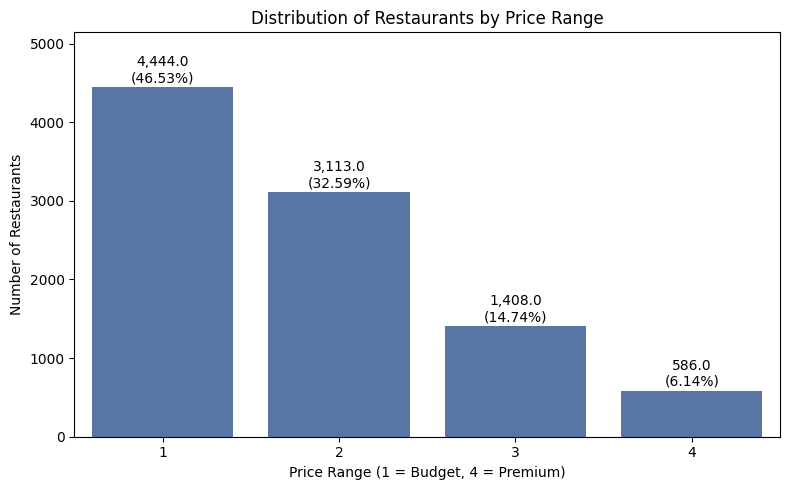

In [16]:
plt.figure(figsize=(8, 5))
ax = sns.barplot(
    data=task3_result,
    x="Price Range",
    y="Restaurant Count",
    color="#4C72B0"
)

for i, row in task3_result.iterrows():
    ax.text(
        i,
        row["Restaurant Count"] + 60,
        f'{row["Restaurant Count"]:,}\n({row["Percentage"]:.2f}%)',
        ha="center"
    )

plt.ylim(0, task3_result["Restaurant Count"].max() + 700)
plt.title("Distribution of Restaurants by Price Range")
plt.xlabel("Price Range (1 = Budget, 4 = Premium)")
plt.ylabel("Number of Restaurants")
plt.tight_layout()
plt.show()

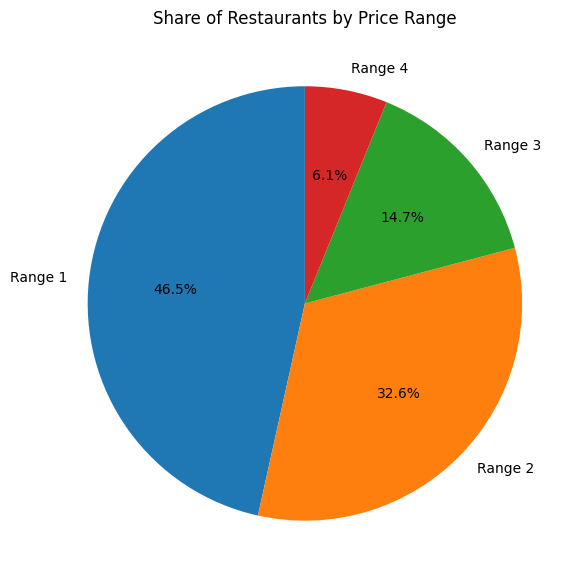

In [17]:
plt.figure(figsize=(6, 6))
plt.pie(
    task3_result["Restaurant Count"],
    labels=[f"Range {p}" for p in task3_result["Price Range"]],
    autopct="%1.1f%%",
    startangle=90
)
plt.title("Share of Restaurants by Price Range")
plt.tight_layout()
plt.show()

## 5. Robustness Check: India vs Rest of the World

In [20]:
india = df["Currency"].str.contains("Indian")

print(f"India share of dataset: {india.mean() * 100:.2f}%")

india_vs_world = pd.DataFrame({
    "India (%)": (df[india]["Price range"].value_counts(normalize=True).sort_index() * 100).round(2),
    "Outside India (%)": (df[~india]["Price range"].value_counts(normalize=True).sort_index() * 100).round(2)
})
india_vs_world

India share of dataset: 90.59%


,India (%),Outside India (%)
Price range,,
1,49.64,16.57
2,33.03,28.36
3,12.84,33.04
4,4.48,22.02


## 6. Validation

In [18]:
print("Total restaurants:", len(df))
print("Sum of price range counts:", price_counts.sum())
print("Counts match:", len(df) == price_counts.sum())
print("Percentages sum to:", round(price_pct.sum(), 2))

Total restaurants: 9551
Sum of price range counts: 9551
Counts match: True
Percentages sum to: 100.0


### Business Insights

- **Price range 1 (budget)** is the largest segment with **4,444 restaurants
  (46.53%)**, so almost half of all listings are low-priced.
- **Price range 2** follows with **3,113 restaurants (32.59%)**. Ranges 1 and 2
  together cover about **79%** of the market.
- **Price range 3** has **1,408 restaurants (14.74%)**.
- **Price range 4 (premium)** is the smallest segment with only **586
  restaurants (6.14%)**.
- Overall, the distribution is heavily skewed toward affordable dining: as
  price goes up, the number of restaurants drops sharply.
- **The overall picture is driven by India.** About **90.59%** of the listings
  use Indian Rupees, so the combined distribution mostly reflects the Indian
  market.
- **The pattern reverses outside India.** There, only 16.57% of restaurants are
  in range 1, while ranges 3 and 4 together make up about 55%. So "premium
  dining is niche" holds for India, not for the other countries.
- **Caution:** `Price range` is a relative tier (1 to 4), not an actual price.
  The same range means a different real cost in different currencies and
  markets (for example, range 1 has a median cost of about Rs. 300 in India but
  about $10 in dollar-based markets), so ranges should not be compared as equal
  prices across countries.